# Analisis Perbandingan 1 Sampel Audio: `asli_human` vs `ai_manipulasi` (`audio_001.wav`)
Notebook ini membedah secara mendalam **di bagian mana letak perbedaan** antara suara manusia asli (`asli_human/audio_001.wav`) dan suara hasil rekayasa AI (`ai_manipulasi/audio_001.wav`) menggunakan **Librosa**.

In [1]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats as stats

path_asli = '../data/dataset_audio_kaggle/asli_human/audio_001.wav'
path_ai   = '../data/dataset_audio_kaggle/ai_manipulasi/audio_001.wav'

# Load kedua audio (masing-masing 30 detik, sr=16000 Hz)
y_asli, sr = librosa.load(path_asli, sr=None)
y_ai, _    = librosa.load(path_ai, sr=None)

def bedah_fitur_audio(y, sr):
    # 1. Domain Waktu (Time-Domain)
    rms = librosa.feature.rms(y=y)[0]
    zcr = librosa.feature.zero_crossing_rate(y=y)[0]
    persen_hening = np.mean(rms < 0.01) * 100  # Persentase waktu jeda/hening

    # 2. Domain Frekuensi / Spektral (Frequency-Domain)
    centroid  = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    rolloff   = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    flatness  = librosa.feature.spectral_flatness(y=y)[0]
    contrast  = librosa.feature.spectral_contrast(y=y, sr=sr)

    # 3. Pitch / Frekuensi Dasar Pita Suara (F0)
    f0 = librosa.yin(y, fmin=50, fmax=400, sr=sr)
    # Filter hanya saat ada suara bicara (bukan hening)
    f0_voiced = f0[rms > 0.01]
    jitter_f0 = np.mean(np.abs(np.diff(f0_voiced)))  # Goyangan mikro pita suara antar-frame

    # 4. Karakteristik Saluran Vokal (MFCC)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfcc_delta = librosa.feature.delta(mfcc)

    return {
        '1. RMS Energy Mean (Kekerasan Suara)': np.mean(rms),
        '2. RMS Energy Std (Fluktuasi/Dinamika Volume)': np.std(rms),
        '3. Persentase Jeda Hening / Napas (%)': persen_hening,
        '4. Zero-Crossing Rate Mean (Ketajaman Desis)': np.mean(zcr),
        '5. Zero-Crossing Rate Std (Variasi Vokal-Konsonan)': np.std(zcr),
        '6. Spectral Centroid Mean (Titik Pusat Frekuensi Hz)': np.mean(centroid),
        '7. Spectral Bandwidth Mean (Lebar Sebaran Frekuensi Hz)': np.mean(bandwidth),
        '8. Spectral Rolloff Mean (Batas Frekuensi Tinggi Hz)': np.mean(rolloff),
        '9. Spectral Flatness Mean (Kerataan Spektrum Sintetis)': np.mean(flatness),
        '10. Spectral Contrast Mean (Ketegasan Puncak Frekuensi dB)': np.mean(contrast),
        '11. Pitch F0 Mean (Rata-rata Nada Bicara Hz)': np.mean(f0_voiced),
        '12. Pitch F0 Std (Variasi Intonasi Nada Hz)': np.std(f0_voiced),
        '13. Pitch Jitter (Goyangan Mikro Pita Suara Hz/frame)': jitter_f0,
        '14. MFCC-1 Mean (Energi Dasar Saluran Vokal)': np.mean(mfcc[0]),
        '15. MFCC-2 Mean (Keseimbangan Frekuensi Rendah-Tinggi)': np.mean(mfcc[1]),
        '16. MFCC-3 Mean (Bentuk Resonansi Rongga Mulut)': np.mean(mfcc[2]),
        '17. Delta MFCC Std (Kecepatan Transisi Artikulasi)': np.std(mfcc_delta),
        '18. Kurtosis Gelombang (Keruncingan Puncak Suara)': stats.kurtosis(y)
    }

fitur_asli = bedah_fitur_audio(y_asli, sr)
fitur_ai   = bedah_fitur_audio(y_ai, sr)

rows = []
for k in fitur_asli:
    v_asli = fitur_asli[k]
    v_ai   = fitur_ai[k]
    selisih_persen = ((v_ai - v_asli) / (abs(v_asli) + 1e-9)) * 100
    rows.append({
        'Bagian / Fitur Audio': k,
        'Manusia Asli (001)': round(v_asli, 4),
        'Manipulasi AI (001)': round(v_ai, 4),
        'Perbedaan (%)': f'{selisih_persen:+.1f}%'
    })

df_perbandingan = pd.DataFrame(rows)
print(df_perbandingan.to_string(index=False))

                                      Bagian / Fitur Audio  Manusia Asli (001)  Manipulasi AI (001) Perbedaan (%)
                      1. RMS Energy Mean (Kekerasan Suara)            0.019200             0.023600        +23.2%
             2. RMS Energy Std (Fluktuasi/Dinamika Volume)            0.009900             0.009600         -3.0%
                     3. Persentase Jeda Hening / Napas (%)           21.108700            10.341200        -51.0%
              4. Zero-Crossing Rate Mean (Ketajaman Desis)            0.096500             0.116500        +20.7%
        5. Zero-Crossing Rate Std (Variasi Vokal-Konsonan)            0.096800             0.095200         -1.7%
      6. Spectral Centroid Mean (Titik Pusat Frekuensi Hz)         1511.016800          1785.312900        +18.2%
   7. Spectral Bandwidth Mean (Lebar Sebaran Frekuensi Hz)         1553.938600          1610.483000         +3.6%
      8. Spectral Rolloff Mean (Batas Frekuensi Tinggi Hz)         2829.607500          

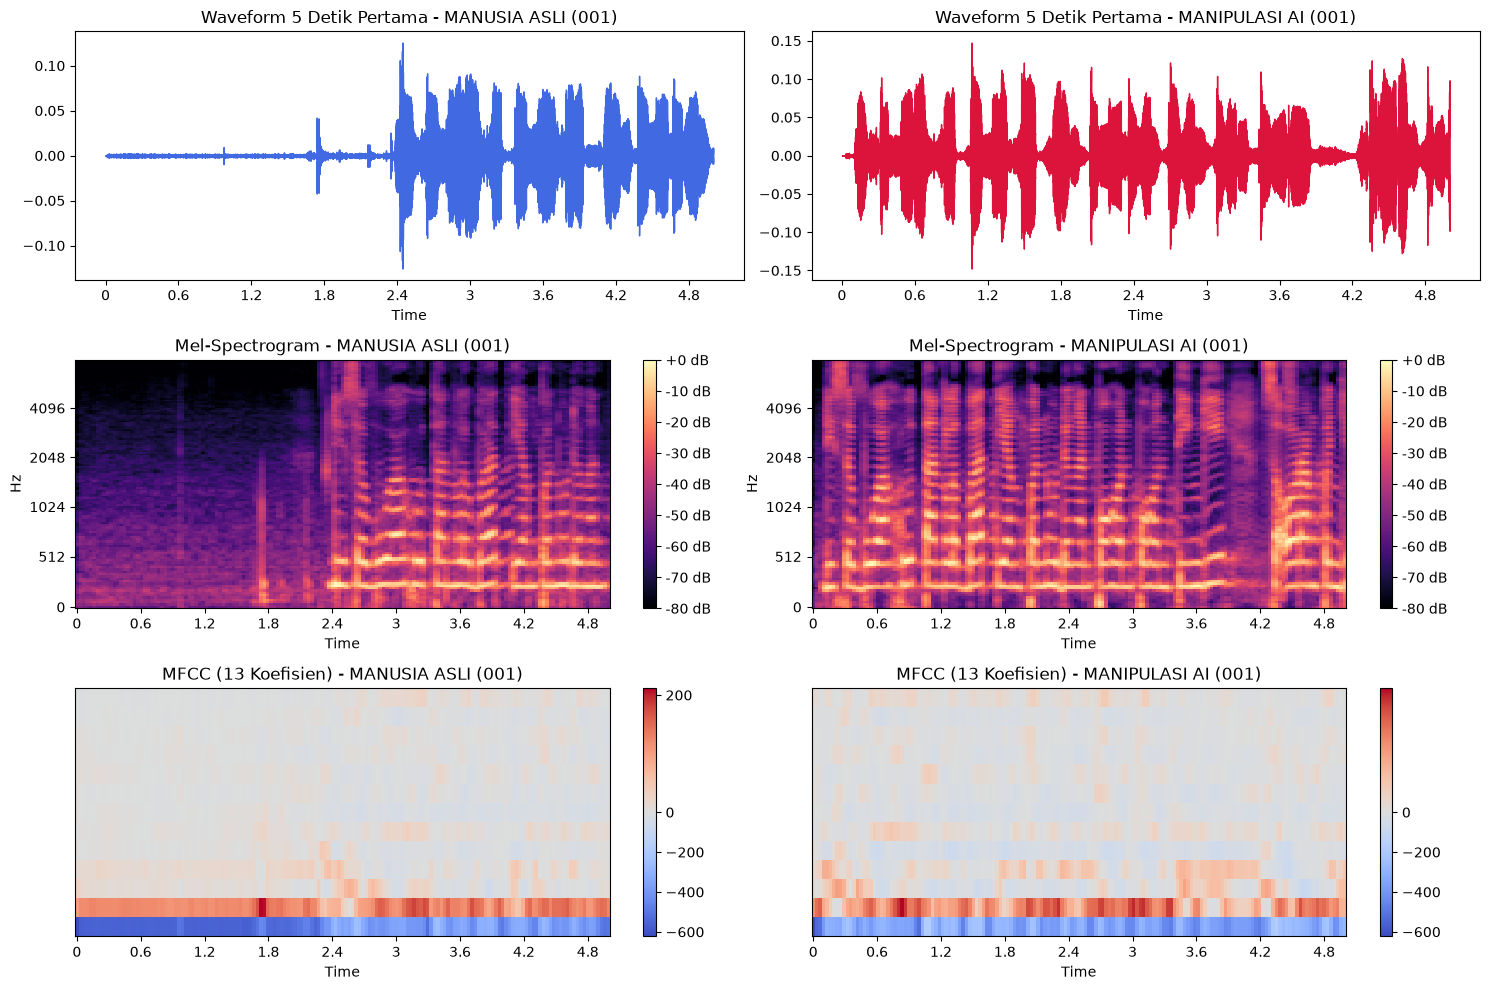

In [2]:
# ==========================================
# VISUALISASI PERBEDAAN GELOMBANG, SPEKTROGRAM, & MFCC
# ==========================================
import librosa.display
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(15, 10))

# 1. Waveform (Ambil 5 detik pertama agar terlihat jelas pola jeda napasnya)
lima_detik = 5 * sr
librosa.display.waveshow(y_asli[:lima_detik], sr=sr, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Waveform 5 Detik Pertama - MANUSIA ASLI (001)')

librosa.display.waveshow(y_ai[:lima_detik], sr=sr, ax=axes[0, 1], color='crimson')
axes[0, 1].set_title('Waveform 5 Detik Pertama - MANIPULASI AI (001)')

# 2. Mel-Spectrogram (Melihat perbedaan frekuensi tinggi & jeda)
S_asli = librosa.power_to_db(librosa.feature.melspectrogram(y=y_asli[:lima_detik], sr=sr), ref=np.max)
img1 = librosa.display.specshow(S_asli, sr=sr, x_axis='time', y_axis='mel', ax=axes[1, 0])
axes[1, 0].set_title('Mel-Spectrogram - MANUSIA ASLI (001)')
fig.colorbar(img1, ax=axes[1, 0], format='%+2.0f dB')

S_ai = librosa.power_to_db(librosa.feature.melspectrogram(y=y_ai[:lima_detik], sr=sr), ref=np.max)
img2 = librosa.display.specshow(S_ai, sr=sr, x_axis='time', y_axis='mel', ax=axes[1, 1])
axes[1, 1].set_title('Mel-Spectrogram - MANIPULASI AI (001)')
fig.colorbar(img2, ax=axes[1, 1], format='%+2.0f dB')

# 3. MFCC (Melihat karakteristik saluran vokal)
mfcc_asli = librosa.feature.mfcc(y=y_asli[:lima_detik], sr=sr, n_mfcc=13)
img3 = librosa.display.specshow(mfcc_asli, sr=sr, x_axis='time', ax=axes[2, 0])
axes[2, 0].set_title('MFCC (13 Koefisien) - MANUSIA ASLI (001)')
fig.colorbar(img3, ax=axes[2, 0])

mfcc_ai = librosa.feature.mfcc(y=y_ai[:lima_detik], sr=sr, n_mfcc=13)
img4 = librosa.display.specshow(mfcc_ai, sr=sr, x_axis='time', ax=axes[2, 1])
axes[2, 1].set_title('MFCC (13 Koefisien) - MANIPULASI AI (001)')
fig.colorbar(img4, ax=axes[2, 1])

plt.tight_layout()
plt.show()